# Car Price Prediction with Machine Learning

This project predicts the selling price of used cars. I use two regression models:
- **Linear Regression** as a simple baseline
- **Random Forest** as a stronger model

Dataset: `car data.csv` (301 rows, 9 columns)

## 1. Import Libraries

Libraries are tools we load at the start. `pandas` handles tables, `matplotlib` draws charts, and `scikit-learn` (sklearn) trains the models.

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the Data

Read the CSV file into a table called `df`, then make all column names lowercase so they are easy to type.

In [62]:
df = pd.read_csv("data/car data.csv")

# make all column names lowercase so they are easy to type
df.columns = df.columns.str.lower()

print(df.shape)
df.head()

(301, 9)


,car_name,year,selling_price,present_price,driven_kms,fuel_type,selling_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Clean the Data

- Remove the 2 duplicate rows.
- Remove `car_name`, because it has too many different values to be useful.

After this step, the table should have **299 rows**.

In [63]:
# remove the 2 duplicate rows
df = df.drop_duplicates()

# remove car_name because it has too many different values
df = df.drop(columns=["car_name"])

print(df.shape)

(299, 8)


## 4. Make a New Feature: Car Age

A model learns from numbers more easily when they mean something. Car age (how many years old the car is) is more useful than the manufacturing year. I use 2026 as the current year.

In [64]:
# car age is easier for a model to learn than the year
df["car_age"] = 2026 - df["year"]

# remove the old year column
df = df.drop(columns=["year"])

## 5. Split Into Inputs (X) and Answer (y)

- **y** is the price we want to predict.
- **X** is everything else the model uses to make its guess.

Text columns (`fuel_type`, `selling_type`, `transmission`) are turned into numbers with `get_dummies`. After this step, there should be **8 features**.

In [65]:
# y is the price we want to predict
y = df["selling_price"]

# X is everything else
X = df.drop(columns=["selling_price"])

# turn text columns into numbers (fuel_type, selling_type, transmission)
X = pd.get_dummies(X, drop_first=True)

print("Number of features:", X.shape[1])

Number of features: 8


## 6. Split Into Training and Testing Data

The model learns from 80% of the cars and is tested on the other 20%. Testing on cars the model has never seen gives a fair score.

In [66]:
# 80% of the cars to train, 20% to test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 7. Train the Models

- **Model 1: Linear Regression** draws a straight-line relationship between the features and the price.
- **Model 2: Random Forest** combines many decision trees and usually predicts better.

In [67]:
# Model 1: Linear Regression (simple baseline)
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Model 2: Random Forest (stronger model)
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

## 8. Check the Results

**What the numbers mean:**
- **MAE:** the average amount the prediction is off, in lakhs. Lower is better.
- **RMSE:** like MAE, but big mistakes count more. Lower is better.
- **R2:** how much of the price change the model explains. Closer to 1 is better.

In [68]:
print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2:", r2_score(y_test, lr_pred))

print()

print("Random Forest")
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2:", r2_score(y_test, rf_pred))

Linear Regression
MAE: 1.472545750817864
RMSE: 2.524504923001876
R2: 0.7527233824220485

Random Forest
MAE: 1.4707091666666667
RMSE: 3.5116977245047267
R2: 0.5215188204751682


## 9. Plot Actual vs Predicted Prices

Each dot is one test car. Dots close to the red line mean good predictions.

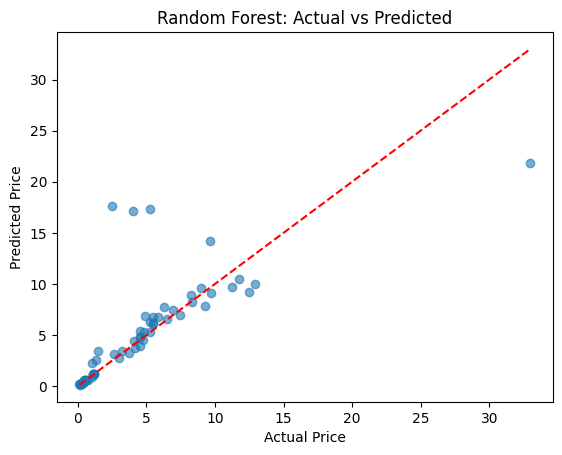

In [69]:
plt.scatter(y_test, rf_pred, alpha=0.6)

# red line = perfect prediction
low = y_test.min()
high = y_test.max()
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

## 10. Which Features Matter Most?

The longest bar is the feature the Random Forest relied on most when making predictions.

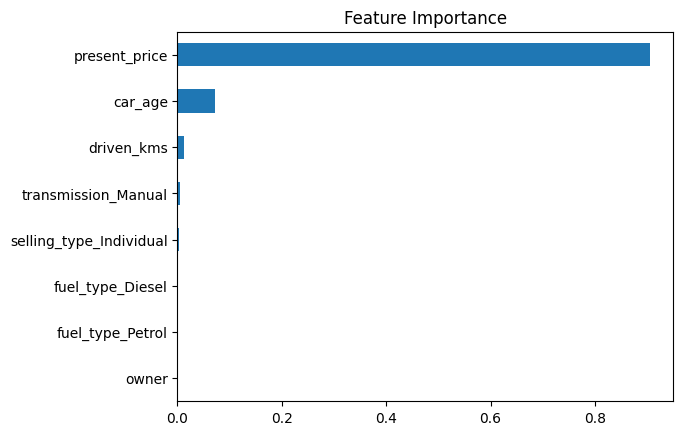

In [70]:
importance = pd.Series(rf.feature_importances_, index=X.columns)

importance.sort_values().plot(kind="barh")
plt.title("Feature Importance")
plt.show()

## Conclusion

Linear Regression performed better than Random Forest on this data. Its R2 was 0.75, compared to 0.52 for Random Forest. Their MAE was almost the same, about 1.47 lakhs for both, but Random Forest had a higher RMSE, 3.51 compared to 2.52 lakhs, because of a few large mistakes. The feature with the longest bar was present_price, with an importance of about 0.9, because a car's original showroom price is the strongest guide to what it is worth used. The Random Forest's large errors came from a few cars with low actual prices that it over-predicted, and one expensive car that it under-predicted. To improve the model, I would check these outliers, try adding more data, and tune the Random Forest settings.